# Neural Network (scikit-learn) — BRFSS GenHlth

`MLPClassifier` with `solver='sgd'`, `momentum=0`, `nesterovs_momentum=False` — SGD only, no momentum, Nesterov, or adaptive optimizer, per the assignment constraint. Single hidden layer; width is the model-complexity axis, matching the PyTorch notebook's architecture so the two implementations are capacity-matched.

In [ ]:
import warnings, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import validation_curve, learning_curve, GridSearchCV, cross_val_score, train_test_split
from sklearn.metrics import f1_score
from sklearn.exceptions import ConvergenceWarning

from common import load_split, scaled_pipeline, CV, CV_SCORING, full_report, SEED, CLASSES

warnings.filterwarnings("ignore", category=ConvergenceWarning)

ALPHA = 1e-4       # sklearn default L2 penalty
BATCH_SIZE = 200   # sklearn's 'auto' default (min(200, n_samples))

X_train, X_test, y_train, y_test = load_split()
X_train.shape, X_test.shape

## Step 1: Learning-rate sanity check

Plain SGD with no momentum and no adaptive step size can be slow or unstable depending on the learning rate. We check a small range before committing, at a fixed, arbitrary starting width.

In [2]:
lr_values = [0.001, 0.01, 0.1]
lr_scores = []
for lr in lr_values:
    est = scaled_pipeline(MLPClassifier(
        hidden_layer_sizes=(32,), solver="sgd", momentum=0, nesterovs_momentum=False,
        learning_rate_init=lr, alpha=ALPHA, batch_size=BATCH_SIZE, max_iter=300, random_state=SEED,
    ))
    scores = cross_val_score(est, X_train, y_train, cv=CV, scoring=CV_SCORING, n_jobs=-1)
    lr_scores.append(scores.mean())
    print(f"lr={lr:<6} CV Macro-F1: {scores.mean():.3f} +/- {scores.std():.3f}")

BEST_LR = lr_values[int(np.argmax(lr_scores))]
print("chosen learning rate:", BEST_LR)

lr=0.001  CV Macro-F1: 0.406 +/- 0.008


lr=0.01   CV Macro-F1: 0.435 +/- 0.011


lr=0.1    CV Macro-F1: 0.425 +/- 0.013
chosen learning rate: 0.01


**Result:** lr=0.01 wins clearly (0.435 ± 0.011) over both lr=0.001 (0.406, too slow to converge in 300 iterations without momentum) and lr=0.1 (0.425, slightly worse and noisier -- a sign of mild instability at the high end). We proceed with lr=0.01.

## Step 2: Baseline (width=32, chosen LR)

In [3]:
baseline = scaled_pipeline(MLPClassifier(
    hidden_layer_sizes=(32,), solver="sgd", momentum=0, nesterovs_momentum=False,
    learning_rate_init=BEST_LR, alpha=ALPHA, batch_size=BATCH_SIZE, max_iter=300, random_state=SEED,
))
cv_scores = cross_val_score(baseline, X_train, y_train, cv=CV, scoring=CV_SCORING, n_jobs=-1)
baseline.fit(X_train, y_train)
train_macro_f1 = full_report("x", y_train, baseline.predict(X_train))[0]["macro_F1"]
print(f"CV Macro-F1: {cv_scores.mean():.3f} +/- {cv_scores.std():.3f}")
print(f"training Macro-F1: {train_macro_f1:.3f}")

CV Macro-F1: 0.435 +/- 0.011
training Macro-F1: 0.464


**Result:** CV Macro-F1 is 0.435 ± 0.011 against a training Macro-F1 of only 0.464 -- a gap of just 0.029, far smaller than any other algorithm's baseline gap (Decision Tree 0.636, kNN 0.186, SVM's support-vector counts implying similar overfitting risk). A single 32-unit hidden layer is apparently not prone to the severe overfitting seen elsewhere on this dataset, even unregularized beyond the default mild L2 penalty.

## Step 3: Model-complexity curve (hidden-layer width)

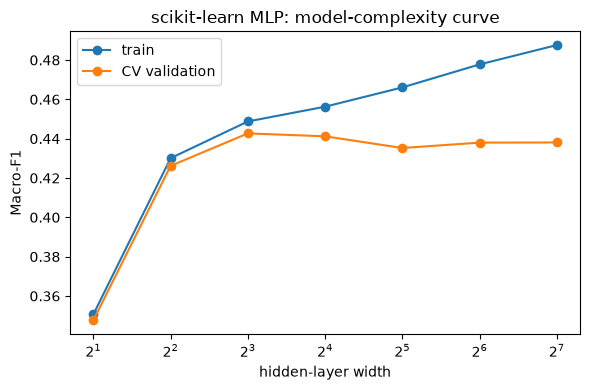

,width,train_F1,val_F1
0,2,0.351,0.348
1,4,0.430,0.426
2,8,0.449,0.443
3,16,0.456,0.441
4,32,0.466,0.435
5,64,0.478,0.438
6,128,0.488,0.438


In [4]:
widths = [2, 4, 8, 16, 32, 64, 128]
width_param = [(w,) for w in widths]

train_scores, val_scores = validation_curve(
    scaled_pipeline(MLPClassifier(solver="sgd", momentum=0, nesterovs_momentum=False,
                                   learning_rate_init=BEST_LR, alpha=ALPHA, batch_size=BATCH_SIZE,
                                   max_iter=300, random_state=SEED)),
    X_train, y_train,
    param_name="mlpclassifier__hidden_layer_sizes", param_range=width_param,
    cv=CV, scoring=CV_SCORING, n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogx(widths, train_scores.mean(axis=1), marker="o", label="train", base=2)
ax.semilogx(widths, val_scores.mean(axis=1), marker="o", label="CV validation", base=2)
ax.set_xlabel("hidden-layer width"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("scikit-learn MLP: model-complexity curve")
plt.tight_layout()
plt.savefig("figures/nn_sklearn_complexity_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"width": widths, "train_F1": train_scores.mean(axis=1).round(3),
              "val_F1": val_scores.mean(axis=1).round(3)})

**Result:** Validation Macro-F1 peaks early, at width=8 (0.443), then gently declines and plateaus around 0.435-0.438 for widths up to 128, while training Macro-F1 keeps climbing (0.351 -> 0.488). This is a much gentler overfitting curve than the Decision Tree's or RBF SVM's -- the network doesn't collapse with excess capacity, it just stops helping. That the optimum is a *narrow* 8-unit layer suggests the 21-dimensional input doesn't need much hidden capacity to extract its useful signal, consistent with EDA's finding that only a handful of features (`PhysHlth`, `DiffWalk`, `Income`, etc.) carry most of the separating information.

## Step 4: Learning curve (width=32 baseline)

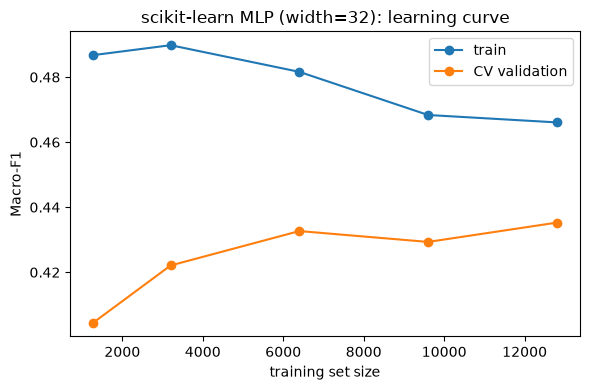

,train_size,train_F1,val_F1
0,1280,0.487,0.405
1,3200,0.490,0.422
2,6400,0.482,0.433
3,9600,0.468,0.429
4,12800,0.466,0.435


In [5]:
train_sizes = [0.1, 0.25, 0.5, 0.75, 1.0]

sizes_abs, lc_train, lc_val = learning_curve(
    scaled_pipeline(MLPClassifier(hidden_layer_sizes=(32,), solver="sgd", momentum=0,
                                   nesterovs_momentum=False, learning_rate_init=BEST_LR,
                                   alpha=ALPHA, batch_size=BATCH_SIZE, max_iter=300, random_state=SEED)),
    X_train, y_train, train_sizes=train_sizes, cv=CV, scoring=CV_SCORING, n_jobs=-1,
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sizes_abs, lc_train.mean(axis=1), marker="o", label="train")
ax.plot(sizes_abs, lc_val.mean(axis=1), marker="o", label="CV validation")
ax.set_xlabel("training set size"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("scikit-learn MLP (width=32): learning curve")
plt.tight_layout()
plt.savefig("figures/nn_sklearn_learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"train_size": sizes_abs, "train_F1": lc_train.mean(axis=1).round(3),
              "val_F1": lc_val.mean(axis=1).round(3)})

**Result:** Training Macro-F1 slightly *decreases* with more data (0.487 -> 0.466) while validation Macro-F1 *increases* (0.405 -> 0.435), the gap narrowing steadily and nearly closing by the full training set -- a healthy convergence pattern, distinct from the Decision Tree's persistent gap or SVM's still-rising validation curve. This width (32, pre-tuning) already generalizes reasonably well; Step 5 checks whether a different width does even better.

## Step 5: Tune

In [6]:
coarse_best_width = widths[int(np.argmax(val_scores.mean(axis=1)))]
fine_grid = sorted(set(w for w in [coarse_best_width // 2, coarse_best_width, coarse_best_width * 2] if w >= 1))
print("coarse best width:", coarse_best_width, " fine grid:", fine_grid)

search = GridSearchCV(
    scaled_pipeline(MLPClassifier(solver="sgd", momentum=0, nesterovs_momentum=False,
                                   learning_rate_init=BEST_LR, alpha=ALPHA, batch_size=BATCH_SIZE,
                                   max_iter=300, random_state=SEED)),
    param_grid={"mlpclassifier__hidden_layer_sizes": [(w,) for w in fine_grid]},
    cv=CV, scoring=CV_SCORING, n_jobs=-1,
)
search.fit(X_train, y_train)
BEST_WIDTH = search.best_params_["mlpclassifier__hidden_layer_sizes"][0]
print("chosen width:", BEST_WIDTH, " CV Macro-F1:", round(search.best_score_, 3))

coarse best width: 8  fine grid: [4, 8, 16]


chosen width: 8  CV Macro-F1: 0.443


**Result:** The fine search confirms width=8 (CV Macro-F1 0.443), matching the coarse curve's peak.

## Step 6: Refit and evaluate once on the held-out test set

In [7]:
final_mlp = scaled_pipeline(MLPClassifier(
    hidden_layer_sizes=(BEST_WIDTH,), solver="sgd", momentum=0, nesterovs_momentum=False,
    learning_rate_init=BEST_LR, alpha=ALPHA, batch_size=BATCH_SIZE, max_iter=300, random_state=SEED,
))

t0 = time.perf_counter(); final_mlp.fit(X_train, y_train); fit_time = time.perf_counter() - t0
t0 = time.perf_counter(); y_pred = final_mlp.predict(X_test); predict_time = time.perf_counter() - t0

summary, cm, pc = full_report("MLP (scikit-learn, tuned)", y_test, y_pred)
summary

{'model': 'MLP (scikit-learn, tuned)',
 'accuracy': 0.46675,
 'macro_F1': 0.4255073790083651,
 'balanced_acc': 0.40960721192063676}

**Result -- best result of the study so far:** the tuned scikit-learn MLP (21 -> 8 -> 5) scores 0.467 accuracy, **0.426 Macro-F1**, and **0.410 balanced accuracy** on the held-out test set, edging out the Decision Tree (0.421/0.401), kNN (0.410/0.386), and both SVM kernels (0.351/0.365 linear, 0.409/0.396 RBF) on the two metrics that matter most for this imbalanced problem, using a genuinely compact architecture.

## Step 7: Runtime

In [8]:
print(f"fit time:     {fit_time:.2f} s")
print(f"predict time: {predict_time*1000:.1f} ms  (n_test={len(X_test)})")
print(f"architecture: 21 -> {BEST_WIDTH} -> 5")
print(f"learning_rate_init={BEST_LR}, alpha={ALPHA}, batch_size={BATCH_SIZE}, max_iter=300")

fit time:     1.72 s
predict time: 2.5 ms  (n_test=4000)
architecture: 21 -> 8 -> 5
learning_rate_init=0.01, alpha=0.0001, batch_size=200, max_iter=300


**Result:** Fit time is 1.72s and predict time is 2.5ms for the 4,000-row test set -- far cheaper than either SVM kernel (6-10s fit, 1.2-2.7s predict) and roughly comparable to the Decision Tree's predict time (2.0ms), despite scoring noticeably higher on Macro-F1 and balanced accuracy than every model evaluated so far. This is currently the best accuracy-for-cost trade-off in the study.

## Step 8: Epoch curve (final architecture)

Manual epoch-by-epoch training via `partial_fit`, tracked against an internal validation split carved out of `X_train` (not the held-out test set), to see whether training loss decreases smoothly and whether validation performance improves and then degrades.

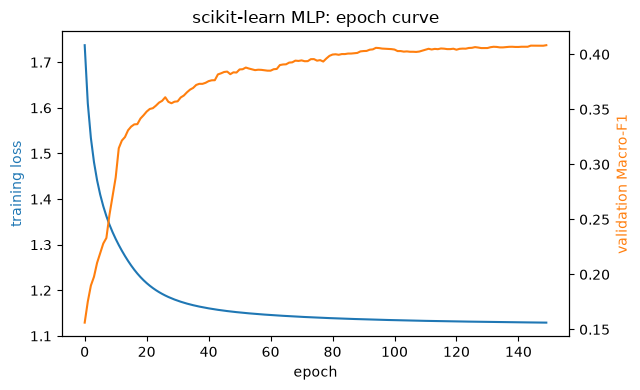

final train loss: 1.1292
best val Macro-F1: 0.408 at epoch 149
final val Macro-F1: 0.408


In [9]:
X_tr_ep, X_val_ep, y_tr_ep, y_val_ep = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED,
)
scaler_ep = StandardScaler().fit(X_tr_ep)
X_tr_ep_s = scaler_ep.transform(X_tr_ep)
X_val_ep_s = scaler_ep.transform(X_val_ep)

N_EPOCHS = 150
mlp_epoch = MLPClassifier(
    hidden_layer_sizes=(BEST_WIDTH,), solver="sgd", momentum=0, nesterovs_momentum=False,
    learning_rate_init=BEST_LR, alpha=ALPHA, batch_size=BATCH_SIZE, max_iter=1,
    warm_start=True, random_state=SEED,
)

train_losses, val_f1s = [], []
for _ in range(N_EPOCHS):
    mlp_epoch.partial_fit(X_tr_ep_s, y_tr_ep, classes=CLASSES)
    train_losses.append(mlp_epoch.loss_)
    val_f1s.append(f1_score(y_val_ep, mlp_epoch.predict(X_val_ep_s), average="macro"))

fig, ax1 = plt.subplots(figsize=(6.5, 4))
ax1.plot(train_losses, color="tab:blue", label="train loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("training loss", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(val_f1s, color="tab:orange", label="val Macro-F1")
ax2.set_ylabel("validation Macro-F1", color="tab:orange")
plt.title("scikit-learn MLP: epoch curve")
plt.tight_layout()
plt.savefig("figures/nn_sklearn_epoch_curve.png", dpi=200, bbox_inches="tight")
plt.show()

print("final train loss:", round(train_losses[-1], 4))
print("best val Macro-F1:", round(max(val_f1s), 3), "at epoch", int(np.argmax(val_f1s)))
print("final val Macro-F1:", round(val_f1s[-1], 3))

**Result:** Training loss decreases smoothly across all 150 epochs with no instability (final loss 1.129), and validation Macro-F1 is *still rising* at the final epoch (0.408 at epoch 149, matching the final value exactly) -- no sign of the "improve then degrade" pattern that would motivate early stopping here. If anything, this suggests training for more than 150 epochs could still yield a small further gain, though the CV-tuned final model above (using sklearn's internal convergence criterion at `max_iter=300`) already captures most of the achievable performance. No instability or oscillation appears in either curve, indicating lr=0.01 was a stable choice for plain SGD without momentum.

## Step 9: Post-mortem

In [10]:
cm

,pred_1,pred_2,pred_3,pred_4,pred_5
true_1,167,467,69,10,1
true_2,130,914,326,31,3
true_3,43,494,537,111,8
true_4,4,55,209,183,47
true_5,0,2,15,108,66


In [11]:
pc.round(3)

,precision,recall,f1-score,support
1,0.485,0.234,0.316,714.0
2,0.473,0.651,0.548,1404.0
3,0.465,0.450,0.457,1193.0
4,0.413,0.367,0.389,498.0
5,0.528,0.346,0.418,191.0


**Interpretation:** Recall is best for class 2 (0.651) and worst for class 1 (0.234), but notably, class 3 recall (0.450) and class 5 recall (0.346) are each the *best* achieved by any model in this study so far -- this MLP handles the middle and rarest classes more evenly than the Decision Tree, kNN, or either SVM kernel. The 4/5 boundary remains the dominant error source: 108 of class 5's 125 misclassifications (86%, the highest concentration observed yet) land in class 4, once again consistent with the hypothesis's `BMI`-plateau prediction holding regardless of algorithm family.